# 03 · Coverage — how much of NM does the scorecard actually cover?

Question 2. CMS only publishes a quality value when a hospital has enough cases.
This notebook measures where that leaves gaps: which hospitals, and which parts of
New Mexico, have little or no reportable data.

`reported` (in `hospital_measures.csv`) is True when a measure has a value, False
when CMS suppressed it. Coverage = the share of measures that are reported.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src.viz import apply_style, CATEGORICAL, BETTER, WORSE, NO_DIFFERENT, INK2, MUTED
apply_style()

PROCESSED = Path("../data/processed")
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

measures = pd.read_csv(PROCESSED / "hospital_measures.csv")
hospitals = pd.read_csv(PROCESSED / "hospitals.csv")
print("measures:", len(measures), "| hospitals:", len(hospitals))

measures: 4182 | hospitals: 45


## 1) Reported share by source

A first look: even before geography, most hospital-measures can't be scored.

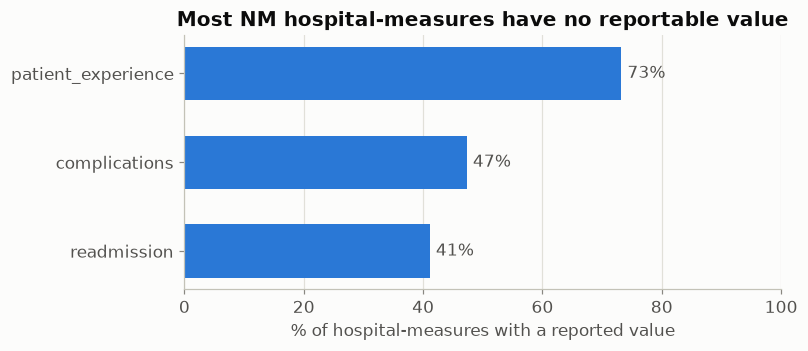

source
readmission           41.1
complications         47.3
patient_experience    73.2
Name: reported, dtype: float64


In [2]:
by_source = measures.groupby("source")["reported"].mean().mul(100).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.0))
bars = ax.barh(by_source.index, by_source.values, color=CATEGORICAL[0], height=0.6)
ax.bar_label(bars, fmt="%.0f%%", padding=4, color=INK2)
ax.set_xlim(0, 100)
ax.set_xlabel("% of hospital-measures with a reported value")
ax.set_title("Most NM hospital-measures have no reportable value")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "fig_coverage_by_source.png")
plt.show()
print(by_source.round(1))

## 2) Coverage by rural/urban — the gap

Break the same measures out by the hospital's RUCA group. This is the core of
question 2.

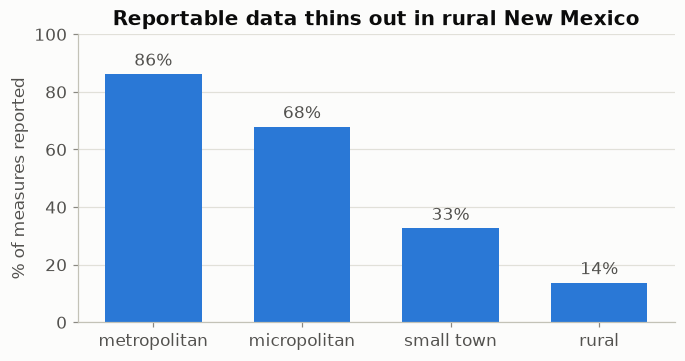

rural_urban
metropolitan    86.1
micropolitan    67.9
small town      32.6
rural           13.7
Name: reported, dtype: float64


In [3]:
order = ["metropolitan", "micropolitan", "small town", "rural"]
by_ru = measures.groupby("rural_urban")["reported"].mean().mul(100).reindex(order)

fig, ax = plt.subplots(figsize=(7, 3.4))
bars = ax.bar(by_ru.index, by_ru.values, color=CATEGORICAL[0], width=0.65)
ax.bar_label(bars, fmt="%.0f%%", padding=3, color=INK2)
ax.set_ylim(0, 100)
ax.set_ylabel("% of measures reported")
ax.set_title("Reportable data thins out in rural New Mexico")
ax.grid(axis="x", visible=False)
fig.savefig(FIG / "fig_coverage_by_rural_urban.png")
plt.show()
print(by_ru.round(1))

## 3) Coverage by Critical Access status

Critical Access hospitals (small, rural) are often excluded from CMS programs and
have low volumes, so we expect less reportable data.

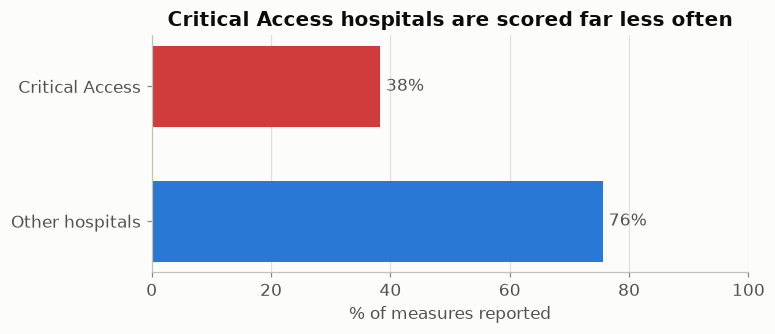

is_critical_access
Other hospitals    75.6
Critical Access    38.2
Name: reported, dtype: float64


In [4]:
by_cah = (
    measures.groupby("is_critical_access")["reported"].mean().mul(100)
    .rename({False: "Other hospitals", True: "Critical Access"})
)

fig, ax = plt.subplots(figsize=(7, 2.8))
bars = ax.barh(by_cah.index, by_cah.values, color=[CATEGORICAL[0], WORSE], height=0.6)
ax.bar_label(bars, fmt="%.0f%%", padding=4, color=INK2)
ax.set_xlim(0, 100)
ax.set_xlabel("% of measures reported")
ax.set_title("Critical Access hospitals are scored far less often")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "fig_coverage_by_critical_access.png")
plt.show()
print(by_cah.round(1))

## 4) Hospital-level: who even gets an overall star rating?

The CMS overall star is the single headline number a patient would look for. How
many of the 45 NM hospitals have one, by rural/urban group?

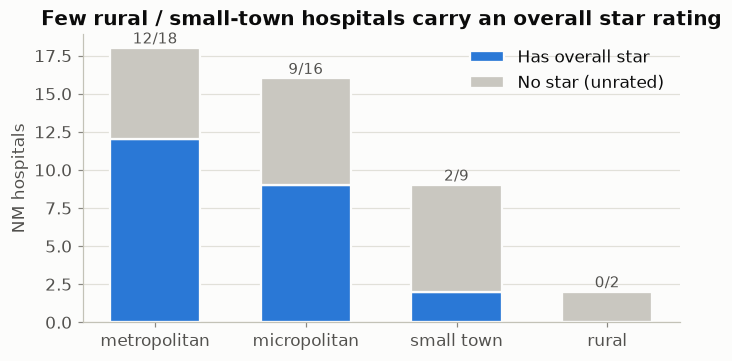

              with_star  total  without
rural_urban                            
metropolitan         12     18        6
micropolitan          9     16        7
small town            2      9        7
rural                 0      2        2

Critical Access with an overall star: 3 of 13
Psychiatric hospitals: 4 | their rows in hospital_measures: 0


In [5]:
hospitals["has_star"] = hospitals["overall_rating"].notna()
tab = (
    hospitals.groupby("rural_urban")["has_star"]
    .agg(with_star="sum", total="count")
    .reindex(order)
)
tab["without"] = tab["total"] - tab["with_star"]

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(tab.index, tab["with_star"], color=BETTER, width=0.6,
       edgecolor="#fcfcfb", linewidth=1.5, label="Has overall star")
ax.bar(tab.index, tab["without"], bottom=tab["with_star"], color=NO_DIFFERENT, width=0.6,
       edgecolor="#fcfcfb", linewidth=1.5, label="No star (unrated)")
for i, (_, r) in enumerate(tab.iterrows()):
    ax.text(i, r["total"] + 0.3, f"{int(r['with_star'])}/{int(r['total'])}",
            ha="center", color=INK2, fontsize=10)
ax.set_ylabel("NM hospitals")
ax.set_title("Few rural / small-town hospitals carry an overall star rating")
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="x", visible=False)
fig.savefig(FIG / "fig_star_coverage_by_group.png")
plt.show()
print(tab)

# traceable for the takeaway:
ca = hospitals[hospitals["is_critical_access"]]
print("\nCritical Access with an overall star:", int(ca["has_star"].sum()), "of", len(ca))
psy = hospitals[hospitals["hospital_type"] == "Psychiatric"]["facility_id"]
print("Psychiatric hospitals:", len(psy),
      "| their rows in hospital_measures:", int(measures["facility_id"].isin(psy).sum()))

## Takeaway — coverage (question 2)

- **Most measures are unreported.** Reported share: 
  - readmission: **41%**
  - complications: **47%**
  - patient experience: **73%** (patient survey covers more because it needs surveys, not case minimums).
  
- **The gap tracks rurality.** Reported share falls from 
  - **86%** metropolitan
    **68%** micropolitan 
    **33%** small town 
    **14%** rural
- **Critical Access hospitals** are scored on **38%** of measures vs **76%** for other
  hospitals.
- **Overall star rating:** **0 of 2** rural and **2 of 9** small-town hospitals have one;
  only **3 of 13** Critical Access hospitals do.
- **Implication:** a CMS-based scorecard largely describes metro/urban NM. 
For rural and Critical Access hospitals, a health plan would need another data source (e.g. its own claims) to measure quality. The 4 Psychiatric hospitals have no measure rows at all.